# Configuration


In [34]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_selection import VarianceThreshold
from sklearn.ensemble import IsolationForest
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import ParameterSampler
from sklearn.metrics import silhouette_score
from sklearn.cluster import KMeans
from itertools import combinations

import warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)

In [2]:
# Load the dataset
accidents_df = pd.read_csv('../data/US_Accidents_March23_sampled_500k.csv')

# Data Preprocessing


In [3]:
# different feature groups we could investigate for clustering
WEATHER_COLUMNS = [
    "Temperature(F)", "Wind_Chill(F)", "Humidity(%)", "Pressure(in)", "Visibility(mi)", 
    "Wind_Speed(mph)", "Precipitation(in)", "Wind_Direction", "Weather_Condition"
]
TEMPORAL_COLUMNS = [
    "Start_Time", "End_Time", "Sunrise_Sunset", "Civil_Twilight", "Nautical_Twilight",
    "Astronomical_Twilight"
]
GEOGRAPHIC_COLUMNS= [
    "Start_Lat", "Start_Lng", "End_Lat", "End_Lng", "City", "County", "State", 
    "Zipcode", "Timezone", "Airport_Code", "Street", "Distance(mi)"
]
INFRA_COLUMNS = [
    "Amenity", "Bump", "Crossing", "Give_Way", "Junction", "No_Exit", "Railway", 
    "Roundabout", "Station", "Stop", "Traffic_Calming", "Traffic_Signal"
]
# show what they like
display(accidents_df[WEATHER_COLUMNS + TEMPORAL_COLUMNS + GEOGRAPHIC_COLUMNS + INFRA_COLUMNS].info())
display(accidents_df[WEATHER_COLUMNS].head(2))
display(accidents_df[TEMPORAL_COLUMNS].head(2))
display(accidents_df[GEOGRAPHIC_COLUMNS].head(2))
display(accidents_df[INFRA_COLUMNS].head(2))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500000 entries, 0 to 499999
Data columns (total 39 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   Temperature(F)         489534 non-null  float64
 1   Wind_Chill(F)          370983 non-null  float64
 2   Humidity(%)            488870 non-null  float64
 3   Pressure(in)           491072 non-null  float64
 4   Visibility(mi)         488709 non-null  float64
 5   Wind_Speed(mph)        463013 non-null  float64
 6   Precipitation(in)      357384 non-null  float64
 7   Wind_Direction         488803 non-null  object 
 8   Weather_Condition      488899 non-null  object 
 9   Start_Time             500000 non-null  object 
 10  End_Time               500000 non-null  object 
 11  Sunrise_Sunset         498517 non-null  object 
 12  Civil_Twilight         498517 non-null  object 
 13  Nautical_Twilight      498517 non-null  object 
 14  Astronomical_Twilight  498517 non-nu

None

,Temperature(F),Wind_Chill(F),Humidity(%),Pressure(in),Visibility(mi),Wind_Speed(mph),Precipitation(in),Wind_Direction,Weather_Condition
0,77.0,77.0,62.0,29.92,10.0,5.0,0.0,NW,Fair
1,45.0,43.0,48.0,29.91,10.0,5.0,0.0,W,Fair


,Start_Time,End_Time,Sunrise_Sunset,Civil_Twilight,Nautical_Twilight,Astronomical_Twilight
0,2019-06-12 10:10:56,2019-06-12 10:55:58,Day,Day,Day,Day
1,2022-12-03 23:37:14.000000000,2022-12-04 01:56:53.000000000,Night,Night,Night,Night


,Start_Lat,Start_Lng,End_Lat,End_Lng,City,County,State,Zipcode,Timezone,Airport_Code,Street,Distance(mi)
0,30.641211,-91.153481,NaN,NaN,Zachary,East Baton Rouge,LA,70791-4610,US/Central,KBTR,Highway 19,0.000
1,38.990562,-77.399070,38.990037,-77.398282,Sterling,Loudoun,VA,20164-2813,US/Eastern,KIAD,Forest Ridge Dr,0.056


,Amenity,Bump,Crossing,Give_Way,Junction,No_Exit,Railway,Roundabout,Station,Stop,Traffic_Calming,Traffic_Signal
0,False,False,False,False,False,False,False,False,False,False,False,True
1,False,False,False,False,False,False,False,False,False,False,False,False


In [4]:
# Exclude columns that are not realistic to impute but has substantial data loss
if "Wind_Chill(F)" in WEATHER_COLUMNS:
    WEATHER_COLUMNS.remove("Wind_Chill(F)")
for col in ["End_Lat", "End_Lng", "Zipcode", "Airport_Code"]:
    if col in GEOGRAPHIC_COLUMNS:
        GEOGRAPHIC_COLUMNS.remove(col)
display(accidents_df[WEATHER_COLUMNS + TEMPORAL_COLUMNS + GEOGRAPHIC_COLUMNS + INFRA_COLUMNS].info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500000 entries, 0 to 499999
Data columns (total 34 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   Temperature(F)         489534 non-null  float64
 1   Humidity(%)            488870 non-null  float64
 2   Pressure(in)           491072 non-null  float64
 3   Visibility(mi)         488709 non-null  float64
 4   Wind_Speed(mph)        463013 non-null  float64
 5   Precipitation(in)      357384 non-null  float64
 6   Wind_Direction         488803 non-null  object 
 7   Weather_Condition      488899 non-null  object 
 8   Start_Time             500000 non-null  object 
 9   End_Time               500000 non-null  object 
 10  Sunrise_Sunset         498517 non-null  object 
 11  Civil_Twilight         498517 non-null  object 
 12  Nautical_Twilight      498517 non-null  object 
 13  Astronomical_Twilight  498517 non-null  object 
 14  Start_Lat              500000 non-nu

None

In [5]:
# Drop missing values that are not realistic to impute
preprocessing_df = accidents_df[
    WEATHER_COLUMNS + TEMPORAL_COLUMNS + GEOGRAPHIC_COLUMNS + INFRA_COLUMNS
].dropna(subset=["Sunrise_Sunset", "Timezone", "Visibility(mi)"])

# Convert Start_Time and End_Time to datetime
preprocessing_df["Start_Time"] = pd.to_datetime(preprocessing_df["Start_Time"], format="mixed")
preprocessing_df["End_Time"] = pd.to_datetime(preprocessing_df["End_Time"], format="mixed")

# State-wise imputation on numeric weather features
# First do date-wise, then falls back to month-wise
preprocessing_df["Date"] = pd.to_datetime(preprocessing_df["Start_Time"], format="mixed").dt.date
preprocessing_df["Month"] = pd.to_datetime(preprocessing_df["Start_Time"], format="mixed").dt.month
IMPUTED_FEATURES = [
    "Precipitation(in)", "Humidity(%)", "Pressure(in)",
    "Wind_Speed(mph)", "Visibility(mi)", "Temperature(F)"
]
for col in IMPUTED_FEATURES:
    preprocessing_df[col] = (
        preprocessing_df[col]
        .fillna(preprocessing_df.groupby(["State", "Date"])[col].transform("median"))
        .fillna(preprocessing_df.groupby(["State", "Month"])[col].transform("median"))
    )

# drop the remaining NA values
preprocessing_df = preprocessing_df.dropna()
preprocessing_df.info()


<class 'pandas.core.frame.DataFrame'>
Index: 483131 entries, 0 to 499999
Data columns (total 36 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   Temperature(F)         483131 non-null  float64       
 1   Humidity(%)            483131 non-null  float64       
 2   Pressure(in)           483131 non-null  float64       
 3   Visibility(mi)         483131 non-null  float64       
 4   Wind_Speed(mph)        483131 non-null  float64       
 5   Precipitation(in)      483131 non-null  float64       
 6   Wind_Direction         483131 non-null  object        
 7   Weather_Condition      483131 non-null  object        
 8   Start_Time             483131 non-null  datetime64[ns]
 9   End_Time               483131 non-null  datetime64[ns]
 10  Sunrise_Sunset         483131 non-null  object        
 11  Civil_Twilight         483131 non-null  object        
 12  Nautical_Twilight      483131 non-null  object   

# Feature Engineering

### Questions we are trying to address: What are the characteristics of the accidents that occur under unusual conditions? How are they associated with higher severity?


In [6]:
# Weather Features
WEATHER_FEATURES = [
    "Temperature(F)", "Humidity(%)", "Pressure(in)", "Visibility(mi)",
    "Wind_Speed(mph)", "Precipitation(in)"
]

features_df = preprocessing_df[WEATHER_FEATURES].copy()
weather = preprocessing_df["Weather_Condition"].fillna("").str.lower()
features_df['has_rain'] = weather.str.contains(r"\brain\b|drizzle|drizziling|rainy",case=False,na=False).astype(int)
features_df['has_clouds'] = weather.str.contains(r"\bcloudy\b|cloud|clouds",case=False,na=False).astype(int)
features_df['has_snow'] = weather.str.contains("snow|snowy",case=False,na=False).astype(int)
features_df['is_sunny'] = weather.str.contains("clear",case=False,na=False).astype(int)
features_df['has_fog'] = weather.str.contains("fog|foggy",case=False,na=False).astype(int)

# print distribution
for col in WEATHER_FEATURES:
    display(features_df[col].describe())

display(features_df['has_rain'].value_counts())
display(features_df['has_clouds'].value_counts())
display(features_df['has_snow'].value_counts())
display(features_df['is_sunny'].value_counts())
display(features_df['has_fog'].value_counts())


count    483131.00000
mean         61.66877
std          18.96021
min         -35.00000
25%          49.00000
50%          64.00000
75%          76.00000
max         207.00000
Name: Temperature(F), dtype: float64

count    483131.000000
mean         64.881071
std          22.794354
min           1.000000
25%          48.000000
50%          67.000000
75%          84.000000
max         100.000000
Name: Humidity(%), dtype: float64

count    483131.00000
mean         29.53935
std           1.00276
min           0.12000
25%          29.37000
50%          29.86000
75%          30.03000
max          38.44000
Name: Pressure(in), dtype: float64

count    483131.000000
mean          9.091365
std           2.711775
min           0.000000
25%          10.000000
50%          10.000000
75%          10.000000
max         130.000000
Name: Visibility(mi), dtype: float64

count    483131.000000
mean          7.639911
std           5.317509
min           0.000000
25%           4.600000
50%           7.000000
75%          10.000000
max         822.800000
Name: Wind_Speed(mph), dtype: float64

count    483131.000000
mean          0.009377
std           0.144435
min           0.000000
25%           0.000000
50%           0.000000
75%           0.000000
max          10.090000
Name: Precipitation(in), dtype: float64

has_rain
0    448621
1     34510
Name: count, dtype: int64

has_clouds
0    305379
1    177752
Name: count, dtype: int64

has_snow
0    473061
1     10070
Name: count, dtype: int64

is_sunny
0    430925
1     52206
Name: count, dtype: int64

has_fog
0    476137
1      6994
Name: count, dtype: int64

In [7]:
# Temporal features

# times

# cyclical encoding for season features
SEASON_MAP = {
    12: 0, 1: 0, 2: 0,    # Winter
    3: 1, 4: 1, 5: 1,    # Spring
    6: 2, 7: 2, 8: 2,    # Summer
    9: 3, 10: 3, 11: 3  # Fall
}
preprocessing_df["Season"] = preprocessing_df["Start_Time"].dt.month.map(SEASON_MAP)
features_df["Season_Sin"] = np.sin(2 * np.pi * preprocessing_df["Season"] / 4)
features_df["Season_Cos"] = np.cos(2 * np.pi * preprocessing_df["Season"] / 4)

features_df["IsRushHour"] = (
    preprocessing_df["Start_Time"].dt.hour.between(6, 9) | # early morning
    preprocessing_df["Start_Time"].dt.hour.between(16, 19) # late evening
).astype(int)
features_df["IsWeekend"] = (
    preprocessing_df["Start_Time"].dt.dayofweek >= 5 # Saturday or Sunday
).astype(int)
features_df["Sunrise_Sunset"] = preprocessing_df["Sunrise_Sunset"].map({"Night": 0, "Day": 1})

# print distribution of each newly created feature
display(features_df["IsRushHour"].value_counts())
display(features_df["IsWeekend"].value_counts())
display(features_df["Season_Sin"].value_counts())
display(features_df["Season_Cos"].value_counts())
display(features_df["Sunrise_Sunset"].value_counts())


IsRushHour
0    243867
1    239264
Name: count, dtype: int64

IsWeekend
0    407127
1     76004
Name: count, dtype: int64

Season_Sin
 0.000000e+00    141038
-1.000000e+00    130682
 1.000000e+00    106755
 1.224647e-16    104656
Name: count, dtype: int64

Season_Cos
 1.000000e+00    141038
-1.836970e-16    130682
 6.123234e-17    106755
-1.000000e+00    104656
Name: count, dtype: int64

Sunrise_Sunset
1    334627
0    148504
Name: count, dtype: int64

In [8]:
# geographic features
GEOGRAPHIC_FEATURES = [
    "Start_Lat", "Start_Lng"
]

# Group anything that begins with letters, -, and numbers as a highway
features_df["Has_Highway"] = preprocessing_df["Street"].str.contains(r'^[A-Za-z]+-[0-9]+').astype(int)

# log1p transform right-skewed data
features_df["Distance(mi)"] = np.log1p(preprocessing_df["Distance(mi)"])

# add remaining features
features_df[GEOGRAPHIC_FEATURES] = preprocessing_df[GEOGRAPHIC_FEATURES]

# print distribution of newly created features
display(features_df["Has_Highway"].describe())
display(features_df["Distance(mi)"].describe())
for col in GEOGRAPHIC_FEATURES:
    display(features_df[col].describe())

count    483131.000000
mean          0.337561
std           0.472878
min           0.000000
25%           0.000000
50%           0.000000
75%           1.000000
max           1.000000
Name: Has_Highway, dtype: float64

count    483131.000000
mean          0.273543
std           0.466455
min           0.000000
25%           0.000000
50%           0.026642
75%           0.375693
max           5.270329
Name: Distance(mi), dtype: float64

count    483131.000000
mean         36.188305
std           5.088612
min          24.562117
25%          33.393028
50%          35.795144
75%          40.093154
max          48.999569
Name: Start_Lat, dtype: float64

count    483131.000000
mean        -94.765231
std          17.386616
min        -124.497420
25%        -117.241501
50%         -87.814415
75%         -80.383503
max         -67.484130
Name: Start_Lng, dtype: float64

In [9]:
# infrastructure features
INFRA_FEATURES = [
    "Amenity", "Bump", "Crossing", "Give_Way", "Junction", "No_Exit", "Railway", 
    "Roundabout", "Station", "Stop", "Traffic_Calming", "Traffic_Signal"
]

features_df["Infra_Count"] = preprocessing_df[INFRA_FEATURES].sum(axis=1)
TRAFFIC_CONTROL_FEATURES = ["Traffic_Signal", "Stop", "Give_Way"]
features_df["Has_Traffic_control"] = preprocessing_df[TRAFFIC_CONTROL_FEATURES].any(axis=1).astype(int)
TRANSIT_FEATURES = ["Station", "Railway"]
features_df["Has_Transit"] = preprocessing_df[TRANSIT_FEATURES].any(axis=1).astype(int)
INTERSECTION_FEATURES = ["Crossing", "Junction", "Roundabout"]
features_df["Has_Intersection"] = preprocessing_df[INTERSECTION_FEATURES].any(axis=1).astype(int)


# print distribution
display(features_df["Infra_Count"].value_counts())
display(features_df["Has_Traffic_control"].value_counts())
display(features_df["Has_Transit"].value_counts())
display(features_df["Has_Intersection"].value_counts())

Infra_Count
0    338399
1     97129
2     38346
3      7803
4      1271
5       167
6        15
7         1
Name: count, dtype: int64

Has_Traffic_control
0    397091
1     86040
Name: count, dtype: int64

Has_Transit
0    467301
1     15830
Name: count, dtype: int64

Has_Intersection
0    393102
1     90029
Name: count, dtype: int64

# Model Tuning

### Model Pipeline: Isolation Forest (Anamoly Detection) -> KMeans (Clustering of normal dataset vs. anamoly dataset)

### Isolation Forest


Correlation Matrix before removing highly correlated features:


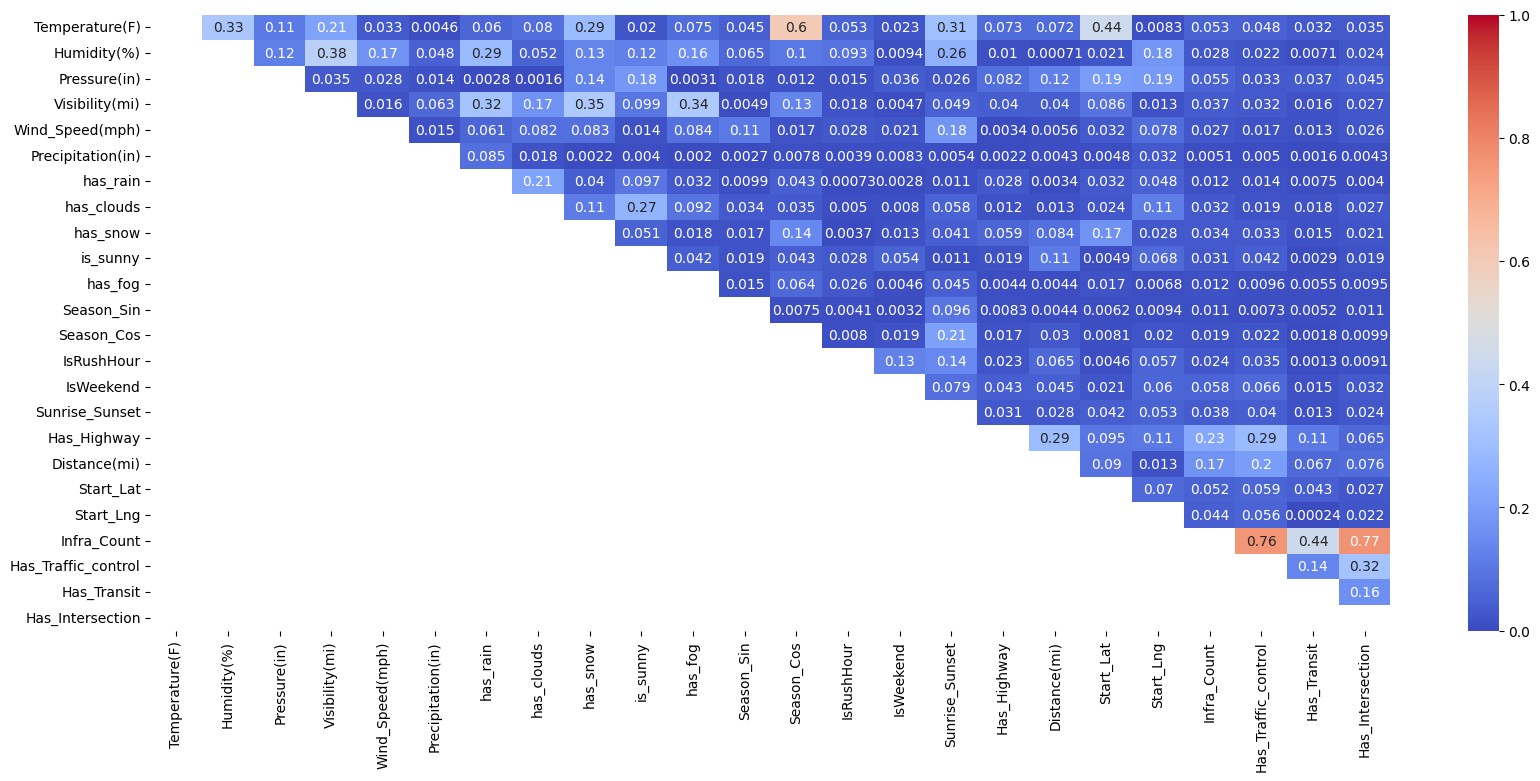

Correlation Matrix after removing highly correlated features:


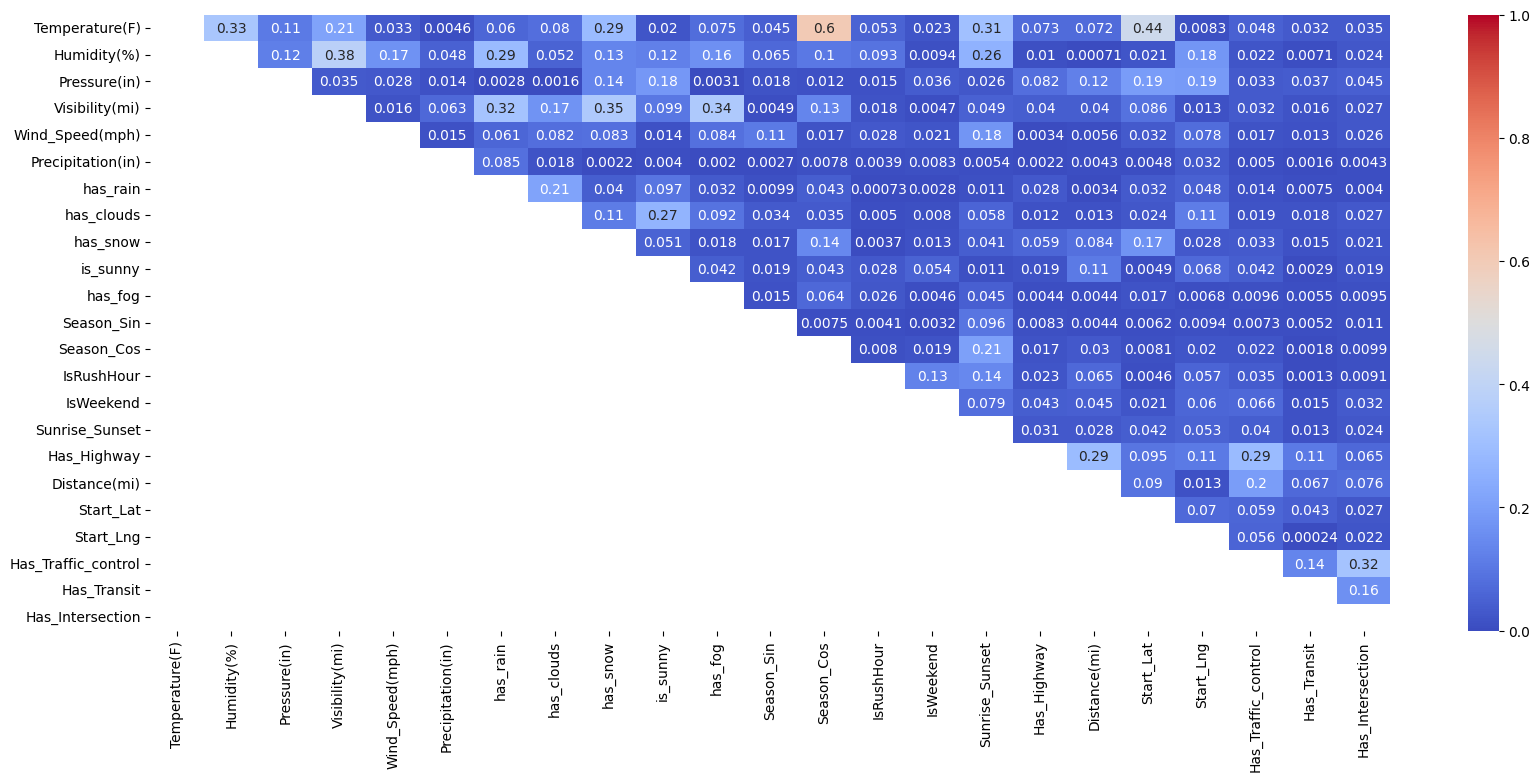

low-variance features to be removed:
Index([], dtype='object')


,Temperature(F),Humidity(%),Pressure(in),Visibility(mi),Wind_Speed(mph),Precipitation(in),has_rain,has_clouds,has_snow,is_sunny,...,IsRushHour,IsWeekend,Sunrise_Sunset,Has_Highway,Distance(mi),Start_Lat,Start_Lng,Has_Traffic_control,Has_Transit,Has_Intersection
0,77.0,62.0,29.92,10.0,5.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.000000,30.641211,-91.153481,1.0,0.0,0.0
1,45.0,48.0,29.91,10.0,5.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.054488,38.990562,-77.399070,0.0,0.0,0.0
2,68.0,73.0,29.79,10.0,13.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,1.0,0.0,0.021761,34.661189,-120.492822,1.0,0.0,0.0
3,27.0,86.0,28.49,10.0,15.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,1.0,0.0,0.719789,43.680592,-92.993317,0.0,0.0,0.0
4,42.0,34.0,29.77,10.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.044973,35.395484,-118.985176,0.0,0.0,0.0


In [ ]:
# Remove redundant (highly correlated) features
pre_corr_matrix = features_df.corr().abs()
pre_mask = np.tril(np.ones_like(pre_corr_matrix, dtype=bool))
selected_df = features_df.drop(columns=["Infra_Count"]) # features with high correlation to others (avg|r| > 0.6)
post_corr_matrix = selected_df.corr().abs()
post_mask = np.tril(np.ones_like(post_corr_matrix, dtype=bool))

print("Correlation Matrix before removing highly correlated features:")
plt.figure(figsize=(20, 8))
sns.heatmap(pre_corr_matrix, mask=pre_mask, annot=True, cmap="coolwarm", vmin=0, vmax=1)
plt.show()

print("Correlation Matrix after removing highly correlated features:")
plt.figure(figsize=(20, 8))
sns.heatmap(post_corr_matrix, mask=post_mask, annot=True, cmap="coolwarm", vmin=0, vmax=1)
plt.show()

# Remove low-variance features
X_selector = VarianceThreshold(threshold=0.01)
X_selected = X_selector.fit_transform(selected_df)
print("low-variance features to be removed:")
print(selected_df.columns[~X_selector.get_support()])

# create final selected df with remaining columns and show
selected_df = pd.DataFrame(
    X_selected, columns=selected_df.columns[X_selector.get_support()],
    index=selected_df.index
)
selected_df.head()


In [36]:
# IsolationForest parameter tuning
SEED = 67
parameter_space = {
    "n_estimators": [200, 300, 400, 500, 600],
    "max_features": [0.4, 0.5, 0.75, 1.0],
    "contamination": [0.03, 0.05, 0.07, 0.10],
}

candidates = []

# Tuning Loop
# Don't use silhouette score since it treats all outliers as a single cluster, which is not really the case
# Use Jaccard similarity coefficient to see if model consistently predicts the same outliers on the validation set
# selects one random outcome each iteration.
N_CANDIDATE_MODELS = 36
for params in ParameterSampler(parameter_space, n_iter=N_CANDIDATE_MODELS,random_state=67):

    # 80% train, 10% validation, 10% test split
    model = IsolationForest(**params, random_state=SEED)
    X_train, X_remaining = train_test_split(selected_df, test_size=0.2, random_state=SEED)
    X_val, X_test = train_test_split(X_remaining, test_size=0.5, random_state=SEED)
    model.fit(X_train)
    train_pred = model.predict(X_train)
    val_pred = model.predict(X_val)

    # calculuates anomaly score for the validation rows.
    validation_scores = -model.score_samples(X_val)

    # saves the candidates so we can compare other models with eachother
    candidates.append({"model" : model, "params": params, "validation_scores" : validation_scores})

# inspect possible candidates
candidates

[{'model': IsolationForest(contamination=0.03, max_features=0.4, n_estimators=200,
                  random_state=67),
  'params': {'n_estimators': 200, 'max_features': 0.4, 'contamination': 0.03},
  'validation_scores': array([0.41831464, 0.42278144, 0.48712486, ..., 0.4833127 , 0.41675816,
         0.50628367])},
 {'model': IsolationForest(contamination=0.05, max_features=0.4, n_estimators=200,
                  random_state=67),
  'params': {'n_estimators': 200, 'max_features': 0.4, 'contamination': 0.05},
  'validation_scores': array([0.41831464, 0.42278144, 0.48712486, ..., 0.4833127 , 0.41675816,
         0.50628367])},
 {'model': IsolationForest(contamination=0.05, max_features=0.4, n_estimators=300,
                  random_state=67),
  'params': {'n_estimators': 300, 'max_features': 0.4, 'contamination': 0.05},
  'validation_scores': array([0.42268589, 0.42094029, 0.48573898, ..., 0.4853656 , 0.4176959 ,
         0.50196818])},
 {'model': IsolationForest(contamination=0.1, max

In [37]:
# Compare candidate stability across different random seeds
# Find the best one 
for candidate in candidates:

    anomaly_sets = []

    for seed in [67, 68, 69, 70, 71]:

        model = IsolationForest(
            **candidate["params"],
            random_state=seed
        )

        model.fit(X_train)

        validation_predictions = model.predict(X_val)

        # Store the row positions predicted as anomalies
        anomaly_sets.append(
            set(np.where(validation_predictions == -1)[0])
        )

    # Calculate pairwise Jaccard similarity
    jaccard_scores = []

    for a, b in combinations(anomaly_sets, 2):

        if len(a | b) == 0:
            jaccard_scores.append(1.0)
        else:
            jaccard_scores.append(
                len(a & b) / len(a | b)
            )

    candidate["jaccard"] = np.mean(jaccard_scores)


# Select the most stable candidate
best_candidate = max(
    candidates,
    key=lambda candidate: candidate["jaccard"]
)
best_params = best_candidate["params"]

print("Selected Parameters:", best_params)
print("Validation Jaccard:", best_candidate["jaccard"])

Selected Parameters: {'n_estimators': 600, 'max_features': 0.4, 'contamination': 0.07}
Validation Jaccard: 0.8304430067017992


In [38]:
# PCA Analysis for anamaly detection
def plot_pca(X, pred, title):
    # Reduce to 2 dimensions
    pca = PCA(n_components=2, svd_solver='full', random_state=SEED)
    pca.fit(X)
    X_pca = pca.transform(X)

    # Plot Anomalous observations
    plt.scatter(X_pca[pred == -1, 0], X_pca[pred == -1, 1], c="red",
        s=5, alpha=0.5, label="Anomaly"
    )

    # Plot Normal observations
    plt.scatter(X_pca[pred == 1, 0], X_pca[pred == 1, 1], c="lightgreen", s=3,
        alpha=0.5, label="Normal"
    )

    plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0] * 100:.2f}%)")
    plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1] * 100:.2f}%)")
    plt.title(title)
    plt.legend()
    plt.show()

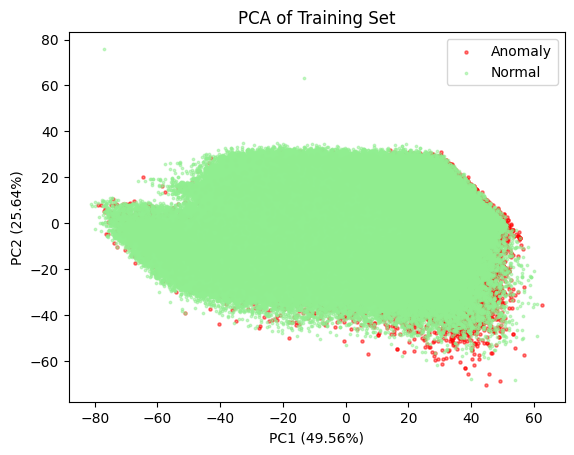

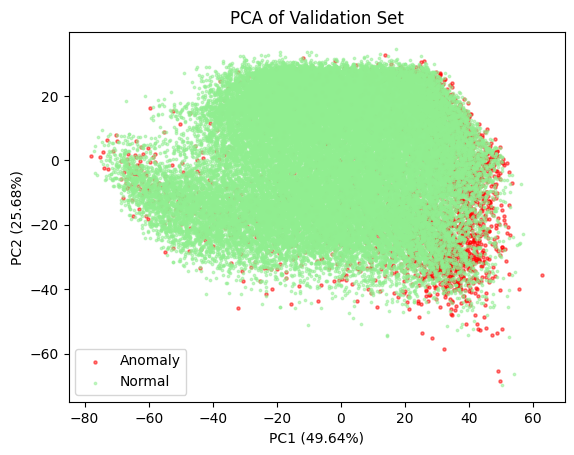

In [39]:
# PCA analysis for the best candidate model
model = IsolationForest(**best_params, random_state=SEED)
model.fit(X_train)
train_pred = model.predict(X_train)
val_pred = model.predict(X_val)
test_pred = model.predict(X_val)

# plot it
plot_pca(X_train, train_pred, "PCA of Training Set")
plot_pca(X_val, val_pred, "PCA of Validation Set")

### KMeans


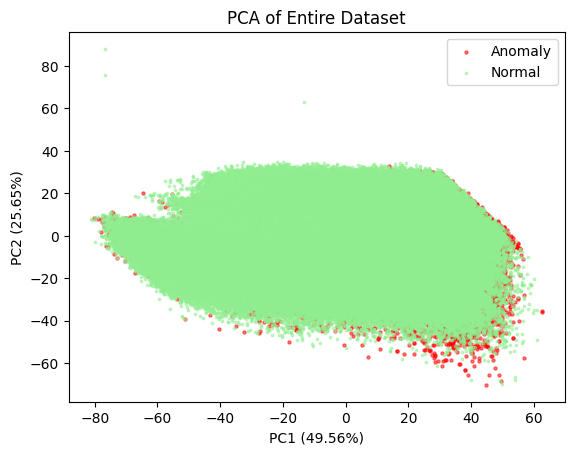

,Temperature(F),Humidity(%),Pressure(in),Visibility(mi),Wind_Speed(mph),Precipitation(in),has_rain,has_clouds,has_snow,is_sunny,...,Season_Sin,Season_Cos,IsRushHour,IsWeekend,Sunrise_Sunset,Has_Highway,Distance(mi),Has_Traffic_control,Has_Transit,Has_Intersection
0,77.0,62.0,29.92,10.0,5.0,0.0,0.0,0.0,0.0,0.0,...,1.224647e-16,-1.0,0.0,0.0,1.0,0.0,0.000000,1.0,0.0,0.0
1,45.0,48.0,29.91,10.0,5.0,0.0,0.0,0.0,0.0,0.0,...,0.000000e+00,1.0,0.0,1.0,0.0,0.0,0.054488,0.0,0.0,0.0


Number of normal observations: 449311


,Temperature(F),Humidity(%),Pressure(in),Visibility(mi),Wind_Speed(mph),Precipitation(in),has_rain,has_clouds,has_snow,is_sunny,...,Season_Sin,Season_Cos,IsRushHour,IsWeekend,Sunrise_Sunset,Has_Highway,Distance(mi),Has_Traffic_control,Has_Transit,Has_Intersection
11,13.0,84.0,24.08,10.0,3.0,0.00,0.0,1.0,0.0,0.0,...,0.0,1.000000e+00,0.0,0.0,0.0,1.0,1.128495,0.0,0.0,0.0
23,62.0,93.0,29.69,8.0,3.0,0.09,1.0,0.0,0.0,0.0,...,1.0,6.123234e-17,1.0,0.0,1.0,0.0,0.000000,1.0,0.0,1.0


Number of abnormal observations: 33820


In [40]:
# Refit optimal Isolation Forest on the entire dataset and predict anomalies
optimal_model = IsolationForest(**best_params, random_state=SEED)
optimal_model.fit(selected_df)
X_pred = optimal_model.predict(selected_df)

# PCA plot
plot_pca(selected_df, X_pred, "PCA of Entire Dataset")

# Add predictions to the original dataset
IF_results = selected_df.copy()
IF_results["Anomaly"] = X_pred

# Split into normal and anomalous datasets
X_normal_df = IF_results[IF_results["Anomaly"] == 1].copy()
X_anomalies_df = IF_results[IF_results["Anomaly"] == -1].copy()

# exclude geographic features for clustering
X_normal_df = X_normal_df.drop(columns=GEOGRAPHIC_FEATURES + ["Anomaly"])
X_anomalies_df = X_anomalies_df.drop(columns=GEOGRAPHIC_FEATURES + ["Anomaly"])

# Check results
display(X_normal_df.head(2))
print(f"Number of normal observations: {len(X_normal_df)}")
display(X_anomalies_df.head(2))
print(f"Number of abnormal observations: {len(X_anomalies_df)}")

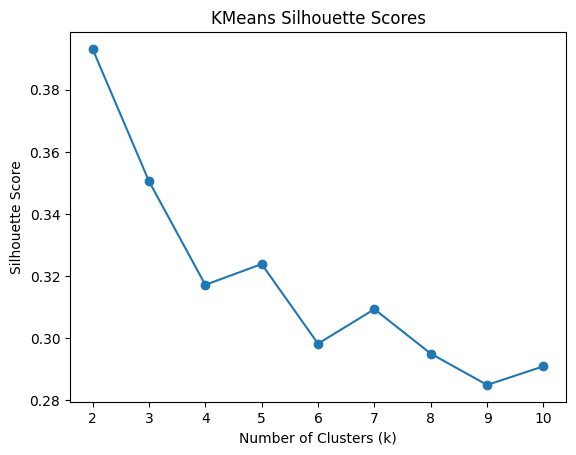

In [41]:
# KMeans Clustering on the normal data

# Only tune k
silhouette_scores = []
for k in range(2, 11):
    model = KMeans(n_clusters=k, random_state=SEED, n_init=20)
    normal_labels = model.fit_predict(X_normal_df)

    silhouette_avg = silhouette_score(
        X_normal_df, normal_labels,
        sample_size=10000,
        random_state=SEED
    )
    silhouette_scores.append(silhouette_avg)

# Plot
plt.plot(range(2, 11), silhouette_scores, marker="o")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")
plt.title("KMeans Silhouette Scores")
plt.show()

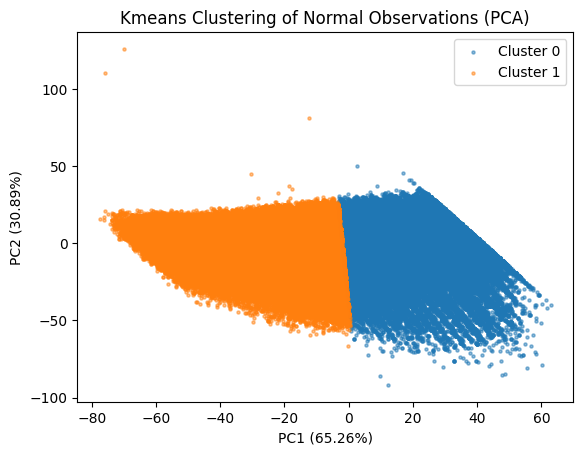

In [42]:
# PCA Analysis for KMeans Clustering
# based on the chart, pick k=2
model = KMeans(n_clusters=2, random_state=SEED, n_init=20)
normal_labels = model.fit_predict(X_normal_df)
pca = PCA(n_components=2, svd_solver="full")
X_pca = pca.fit_transform(X_normal_df)

# Plot each cluster separately
for cluster in np.unique(normal_labels):
    plt.scatter(
        X_pca[normal_labels == cluster, 0],
        X_pca[normal_labels == cluster, 1],
        s=5,
        alpha=0.5,
        label=f"Cluster {cluster}"
    )

plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0] * 100:.2f}%)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1] * 100:.2f}%)")
plt.title("Kmeans Clustering of Normal Observations (PCA)")
plt.legend()
plt.show()

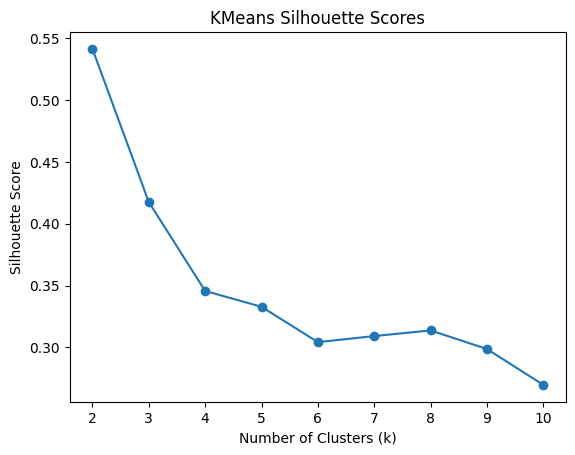

In [43]:
# KMeans Clustering on the anomalous data

# Only tune k
silhouette_scores = []
for k in range(2, 11):
    model = KMeans(n_clusters=k, random_state=SEED, n_init=20)
    labels = model.fit_predict(X_anomalies_df)

    silhouette_avg = silhouette_score(
        X_anomalies_df, labels,
        sample_size=10000,
        random_state=SEED
    )
    silhouette_scores.append(silhouette_avg)

# Plot
plt.plot(range(2, 11), silhouette_scores, marker="o")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")
plt.title("KMeans Silhouette Scores")
plt.show()

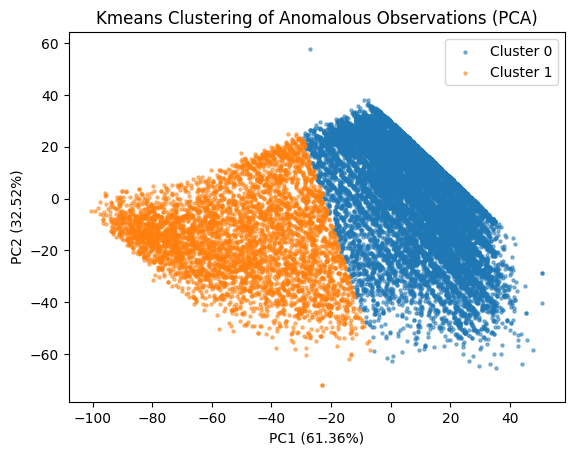

In [44]:
# PCA Analysis for KMeans Clustering
# based on the chart, pick k=2
model = KMeans(n_clusters=2, random_state=SEED, n_init=20)
anomaly_labels = model.fit_predict(X_anomalies_df)
pca = PCA(n_components=2, svd_solver="full")
X_pca = pca.fit_transform(X_anomalies_df)

# Plot each cluster separately
for cluster in np.unique(anomaly_labels):
    plt.scatter(
        X_pca[anomaly_labels == cluster, 0],
        X_pca[anomaly_labels == cluster, 1],
        s=5,
        alpha=0.5,
        label=f"Cluster {cluster}"
    )

plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0] * 100:.2f}%)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1] * 100:.2f}%)")
plt.title("Kmeans Clustering of Anomalous Observations (PCA)")
plt.legend()
plt.show()

# Normal Dataset


In [27]:
# analyze 2 clusters from the normal dataset
normal_df = preprocessing_df.copy()
normal_df = normal_df[IF_results["Anomaly"] == 1].copy()
normal_df["Cluster"] = pd.Series(normal_labels, index=X_normal_df.index)
normal_df.head(4)

,Temperature(F),Humidity(%),Pressure(in),Visibility(mi),Wind_Speed(mph),Precipitation(in),Wind_Direction,Weather_Condition,Start_Time,End_Time,...,Railway,Roundabout,Station,Stop,Traffic_Calming,Traffic_Signal,Date,Month,Season,Cluster
0,77.0,62.0,29.92,10.0,5.0,0.0,NW,Fair,2019-06-12 10:10:56,2019-06-12 10:55:58,...,False,False,False,False,False,True,2019-06-12,6,2,1
1,45.0,48.0,29.91,10.0,5.0,0.0,W,Fair,2022-12-03 23:37:14,2022-12-04 01:56:53,...,False,False,False,False,False,False,2022-12-03,12,0,1
2,68.0,73.0,29.79,10.0,13.0,0.0,W,Fair,2022-08-20 13:13:00,2022-08-20 15:22:45,...,False,False,False,False,False,True,2022-08-20,8,2,0
3,27.0,86.0,28.49,10.0,15.0,0.0,ENE,Wintry Mix,2022-02-21 17:43:04,2022-02-21 19:43:23,...,False,False,False,False,False,False,2022-02-21,2,0,0


In [ ]:
# Weather features visualization


# Anamaly Dataset


In [26]:
anamaly_df = preprocessing_df.copy()
anamaly_df = anamaly_df[IF_results["Anomaly"] == -1].copy()
anamaly_df["Cluster"] = pd.Series(anomaly_labels, index=X_anomalies_df.index)
anamaly_df.head(4)

,Temperature(F),Humidity(%),Pressure(in),Visibility(mi),Wind_Speed(mph),Precipitation(in),Wind_Direction,Weather_Condition,Start_Time,End_Time,...,Railway,Roundabout,Station,Stop,Traffic_Calming,Traffic_Signal,Date,Month,Season,Cluster
11,13.0,84.0,24.08,10.0,3.0,0.00,VAR,Cloudy,2022-02-01 04:13:55,2022-02-01 07:05:30,...,False,False,False,False,False,False,2022-02-01,2,0,0
23,62.0,93.0,29.69,8.0,3.0,0.09,ENE,Light Rain,2022-03-16 18:56:36,2022-03-16 19:26:44,...,False,False,False,False,False,True,2022-03-16,3,1,0
33,37.0,93.0,30.23,0.5,0.0,0.00,CALM,Fog,2021-01-05 01:56:00,2021-01-05 04:46:28,...,False,False,False,False,False,False,2021-01-05,1,0,0
64,32.0,87.0,29.61,6.0,24.2,0.00,NNW,Light Snow,2018-01-22 16:19:44,2018-01-22 17:04:33,...,False,False,False,False,False,True,2018-01-22,1,0,0
